In [ ]:
import numpy as np
import matplotlib.pyplot as plt 

data_train_path = "/workspaces/seismic-datasets/data/original/F3/data/train/train_seismic.npy"
label_train_path = "/workspaces/seismic-datasets/data/original/F3/data/train/train_labels.npy"

val_data_path = "/workspaces/seismic-datasets/data/original/F3/data/test_once/test1_seismic.npy"
val_label_path = "/workspaces/seismic-datasets/data/original/F3/data/test_once/test1_labels.npy"

data_train = np.load(data_train_path).transpose(0, 2, 1)
labels_train = np.load(label_train_path).transpose(0, 2, 1)
data_val = np.load(val_data_path).transpose(0, 2, 1)
labels_val = np.load(val_label_path).transpose(0, 2, 1)

print(f"Train data shape: {data_train.shape}")
print(f"Train labels shape: {labels_train.shape}")
print(f"Validation data shape: {data_val.shape}")
print(f"Validation labels shape: {labels_val.shape}")


print(data_train.shape)
print(labels_train.shape)

Train data shape: (401, 255, 701)
Train labels shape: (401, 255, 701)
Validation data shape: (200, 255, 701)
Validation labels shape: (200, 255, 701)
Test data shape: (601, 255, 200)
Test labels shape: (601, 255, 200)
(401, 255, 701)
(401, 255, 701)


In [ ]:
def plot_sample_and_label(sample, label, sample_index=0):
    plt.figure(figsize=(12, 3))
    plt.subplot(1, 2, 1)
    plt.imshow(sample[sample_index], aspect='auto', cmap='seismic')
    plt.title(f'Seismic Sample {sample_index}')
    plt.colorbar()
    
    plt.subplot(1, 2, 2)
    plt.imshow(label[sample_index], aspect='auto', cmap='gray')
    plt.title(f'Label for Sample {sample_index}')
    plt.colorbar()
    
    plt.tight_layout()
    plt.show()


def plot_sample_and_attributes(sample, envelope, semblance, label, sample_index=0):
    fig = plt.figure(figsize=(20, 5))

    plt.subplot(1, 4, 1)
    plt.imshow(sample[sample_index, :, :], cmap='gray')
    plt.title("Original")
    plt.subplot(1, 4, 2)
    plt.imshow(envelope[sample_index, :, :], cmap='gray')
    plt.title("Envelope")
    plt.subplot(1, 4, 3)
    plt.imshow(semblance[sample_index, :, :], cmap='gray')
    plt.title("Semblance")
    plt.subplot(1, 4, 4)
    plt.imshow(label[sample_index, :, :], cmap="viridis")
    plt.title("Labels")
    plt.show()

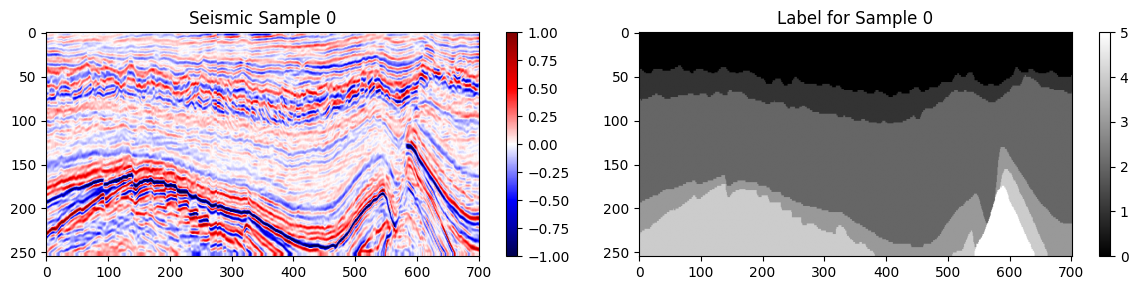

In [3]:
plot_sample_and_label(data_train, labels_train, sample_index=0)

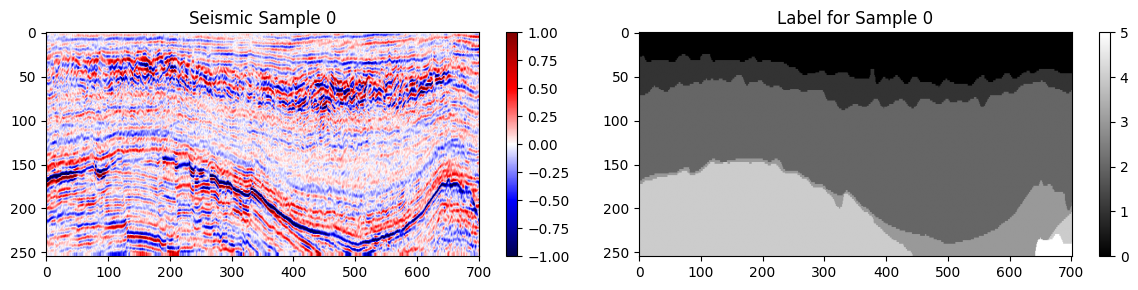

In [4]:
plot_sample_and_label(data_val, labels_val, sample_index=0)

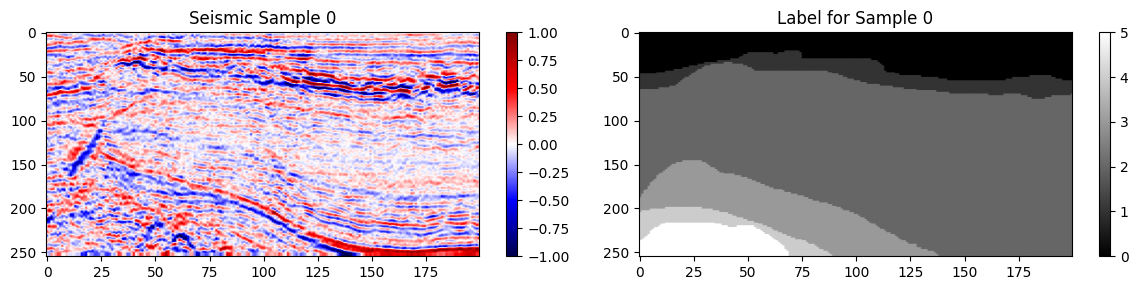

In [5]:
plot_sample_and_label(data_test, labels_test, sample_index=0)

In [6]:
def envelope_numpy(cube: np.ndarray) -> np.ndarray:
    """
    Envelope for 3D seismic cube (x, y, z).
    Computed along z-axis (time/depth).
    """

    cube = np.asarray(cube)
    assert cube.ndim == 3, "Input must be 3D (x, y, z)"

    fft_data = np.fft.fft(cube, axis=2)
    n = cube.shape[2]

    h = np.zeros(n)
    if n % 2 == 0:
        h[0] = h[n // 2] = 1
        h[1:n // 2] = 2
    else:
        h[0] = 1
        h[1:(n + 1) // 2] = 2

    h = h.reshape(1, 1, n)

    analytic = np.fft.ifft(fft_data * h, axis=2)

    return np.abs(analytic)

In [ ]:
import numpy as np
from numpy.lib.stride_tricks import sliding_window_view

def semblance_numpy(
    cube: np.ndarray,
    window_xy: int = 3,
    window_z: int = 9,
) -> np.ndarray:
    """
    Fast vectorized semblance for 3D seismic cube (x, y, z).

    Semablance is the V_rms = sqrt(sum(t_i) * V_i^2 / sum(t_i))

    Parameters
    ----------
    cube : np.ndarray
        Shape (x, y, z)
    window_xy : int
        Spatial window size
    window_z : int
        Time/depth window siz

    Returns
    -------
    np.ndarray
        Semblance cube (same shape as input)
    """

    cube = np.asarray(cube)
    assert cube.ndim == 3, "Input must be 3D (x, y, z)"
    assert window_xy % 2 == 1, "window_xy must be odd"
    assert window_z % 2 == 1, "window_z must be odd"

    pad_x = window_xy // 2
    pad_y = window_xy // 2
    pad_z = window_z // 2

    # Reflect padding (same as typical seismic processing)
    padded = np.pad(
        cube,
        ((pad_x, pad_x), (pad_y, pad_y), (pad_z, pad_z)),
        mode="reflect"
    )

    # Create sliding windows
    # Result shape:
    # (nx, ny, nz, window_xy, window_xy, window_z)
    windows = sliding_window_view(
        padded,
        (window_xy, window_xy, window_z)
    )
    print(f"Windows shape: {windows.shape}")

    # Compute sums
    sum_vals = np.sum(windows, axis=(-3, -2, -1))
    sum_sq_vals = np.sum(windows**2, axis=(-3, -2, -1))

    # Number of samples in window
    N = window_xy * window_xy * window_z

    # Semblance formula
    semblance = (sum_vals ** 2) / (N * sum_sq_vals + 1e-12)

    return semblance.astype(np.float32)

Data shape: (401, 255, 701)
Envelope shape: (401, 255, 701)
Semblance shape: (401, 255, 701)


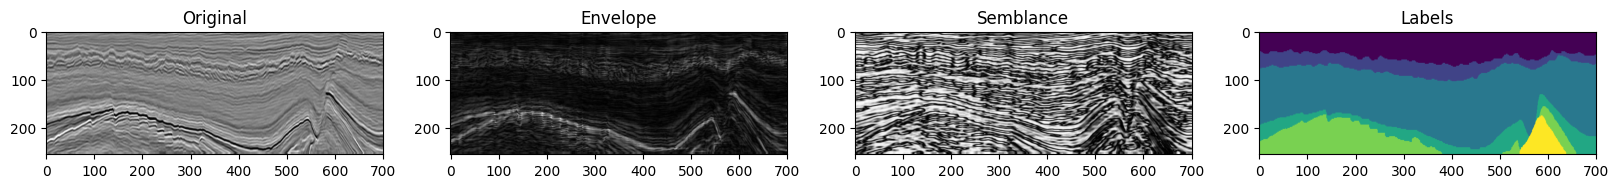

In [8]:
print(f"Data shape: {data_train.shape}")
envelope_data_train = envelope_numpy(data_train)
print(f"Envelope shape: {envelope_data_train.shape}")
semblance_data_train = semblance_numpy(data_train)
print(f"Semblance shape: {semblance_data_train.shape}")

plot_sample_and_attributes(
    data_train, envelope_data_train, semblance_data_train, labels_train, sample_index=0
)

Data shape: (200, 255, 701)
Envelope shape: (200, 255, 701)
Semblance shape: (200, 255, 701)


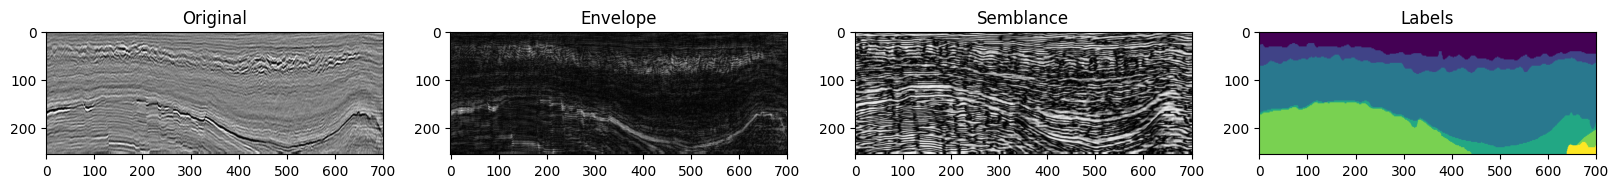

In [9]:
print(f"Data shape: {data_val.shape}")
envelope_data_val = envelope_numpy(data_val)
print(f"Envelope shape: {envelope_data_val.shape}")
semblance_data_val = semblance_numpy(data_val)
print(f"Semblance shape: {semblance_data_val.shape}")

plot_sample_and_attributes(
    data_val, envelope_data_val, semblance_data_val, labels_val, sample_index=0
)

Data shape: (601, 255, 200)
Envelope shape: (601, 255, 200)
Semblance shape: (601, 255, 200)


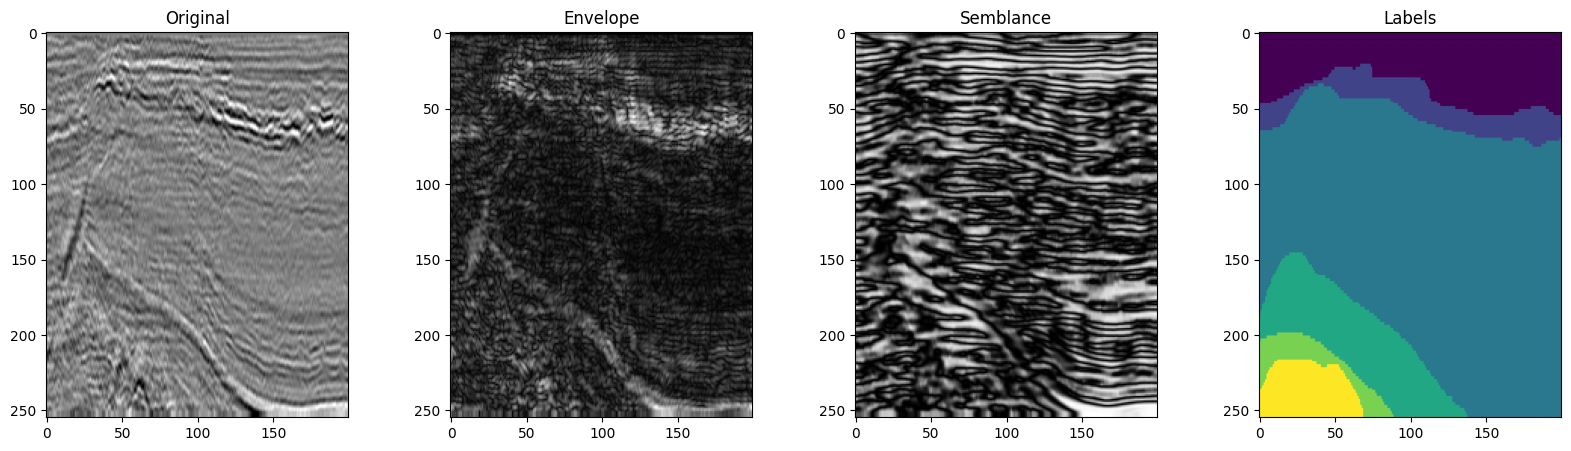

In [10]:
print(f"Data shape: {data_test.shape}")
envelope_data_test = envelope_numpy(data_test)
print(f"Envelope shape: {envelope_data_test.shape}")
semblance_data_test = semblance_numpy(data_test)
print(f"Semblance shape: {semblance_data_test.shape}")

plot_sample_and_attributes(
    data_test, envelope_data_test, semblance_data_test, labels_test, sample_index=0
)